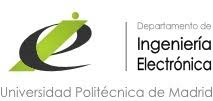

<div align="center">

# **Reconocimiento de Actividades Humanas con Sensores Inerciales (Inertial HAR v2)**
### **Modelado Secuencial con Keras 3.15.1 y Procesado de Señal en Python**
---
</div>

## Introducción y Objetivos de la Práctica

El reconocimiento de actividades humanas (**HAR**, *Human Activity Recognition*) a partir de sensores inerciales (acelerómetros triaxiales $a_x, a_y, a_z$) es una tecnología fundamental en monitorización clínica (detección de temblores en Parkinson, caídas), rehabilitación física, deporte inteligente e interacción persona-máquina.

En este laboratorio trabajaremos con ventanas temporales de **4 segundos** muestreadas a **50 Hz** (intervalo de 20 ms) con la placa **SenseHAT de la Raspberry Pi**, lo que produce **200 instantes temporales por eje** ($200 \times 3 = 600$ valores por muestra).

### Objetivos de la sesión:
1. **Exploración y Visualización de Señales Inerciales**: Analizar la dinámica temporal en 3 ejes y la separabilidad en componentes principales (PCA 3D).
2. **Experimento 1 — Clasificación Clásica sobre Señal Cruda (*Raw Data*)**: Evaluar árboles de decisión y *Random Forests* directamente sobre las 600 muestras temporales y comprender su sensibilidad a desfases temporales.
3. **Experimento 2 — Ingeniería de Características (*Time, Frequency & Cepstral/IMFCC*)**: Extraer descriptores físicos en el dominio del tiempo, frecuencia (FFT/PSD) y cepstral (IMFCC) íntegramente en Python para mejorar los clasificadores clásicos.
4. **Experimento 3 — Aprendizaje Profundo Secuencial (*LSTM / GRU / BiLSTM / Conv1D-LSTM*)**: Entrenar un modelo secuencial en **Keras 3.15.1** alimentado directamente con tensores 3D `(num_samples, 200, 3)` y exportarlo para ejecutar inferencia en tiempo real en la **Raspberry Pi** (`demo-lstm-recognizer.py`).
5. **Experimento 4 — Comparativa Estadística de Sistemas**: Comparar todos los enfoques mediante intervalos de confianza al 95%.

# 0. Preparación del Entorno de Trabajo (*Workspace Setup*)

Ejecuta la sección **0.A** si estás trabajando en **Google Colab**, o la sección **0.B** si ejecutas el notebook en **local**.

## 0.A Ejecución en Google Colab (Montaje de Drive y Clonado del Repositorio)

In [1]:
# 1. Montar Google Drive (opcional, para guardar/cargar datasets propios o modelos)
from google.colab import drive
drive.mount("/content/drive")

# 2. Clonar únicamente las carpetas necesarias del repositorio (Sparse Checkout)
%cd /content
!rm -rf IE-workspace
!git clone --filter=blob:none --no-checkout https://github.com/efhes/IE-workspace.git
%cd /content/IE-workspace
!git sparse-checkout init --cone
!git sparse-checkout set HAR_INERCIAL_v2 HAR_INERCIAL common
!git checkout

Mounted at /content/drive
/content
Cloning into 'IE-workspace'...
remote: Enumerating objects: 493, done.
remote: Counting objects: 100% (110/110), done.
remote: Compressing objects: 100% (83/83), done.
remote: Total 493 (delta 52), reused 76 (delta 25), pack-reused 383 (from 1)
Receiving objects: 100% (493/493), 77.43 KiB | 3.69 MiB/s, done.
Resolving deltas: 100% (195/195), done.
/content/IE-workspace
remote: Enumerating objects: 39, done.
remote: Counting objects: 100% (29/29), done.
remote: Compressing objects: 100% (25/25), done.
remote: Total 39 (delta 7), reused 20 (delta 3), pack-reused 10 (from 1)
Receiving objects: 100% (39/39), 2.88 MiB | 13.55 MiB/s, done.
Resolving deltas: 100% (8/8), done.
Your branch is up to date with 'origin/master'.


In [2]:
# 3. Instalar versiones compatibles con el entorno de la Raspberry Pi (keras 3.15.1 y mediapipe 1.2.3)
!pip install -q keras==3.15.1 mediapipe==1.2.3 scikit-learn scipy pandas numpy matplotlib seaborn

In [3]:
import os
import sys

# Configurar ruta base del proyecto en Google Colab
if os.path.exists("/content/IE-workspace/HAR_INERCIAL_v2"):
    general_path = "/content/IE-workspace/HAR_INERCIAL_v2"
elif os.path.exists("/content/drive/MyDrive/HAR_INERCIAL_v2"):
    general_path = "/content/drive/MyDrive/HAR_INERCIAL_v2"
else:
    general_path = "/content/IE-workspace/HAR_INERCIAL"

src_path = os.path.join(general_path, "src")
common_path = "/content/IE-workspace/common"

for p in [general_path, src_path, common_path]:
    if os.path.exists(p) and p not in sys.path:
        sys.path.insert(0, p)

print("✅ general_path configurado en:", general_path)

✅ general_path configurado en: /content/IE-workspace/HAR_INERCIAL_v2


## 0.B Ejecución en Ordenador Local (*Solo si NO usas Google Colab*)

In [ ]:
%pip install -q keras==3.15.1 mediapipe==1.2.3 scikit-learn scipy pandas numpy matplotlib seaborn

In [ ]:
import os
import sys

general_path = os.path.abspath(os.path.expanduser("~/workspace/IE-workspace/HAR_INERCIAL_v2"))
src_path = os.path.join(general_path, "src")
common_path = os.path.abspath(os.path.expanduser("~/workspace/IE-workspace/common"))

for p in [general_path, src_path, common_path]:
    if os.path.exists(p) and p not in sys.path:
        sys.path.insert(0, p)

print("✅ general_path local configurado en:", general_path)

## 0.C Importación de Librerías del Proyecto y Verificación de Versiones

In [4]:
import importlib
import numpy as np
import pandas as pd
import tensorflow as tf
import keras

import notebook.har_utils as hu
import notebook.feature_utils as fu
import notebook.model_utils as mu
import notebook.display_utils as display

importlib.reload(hu)
importlib.reload(fu)
importlib.reload(mu)
importlib.reload(display)

print("🚀 Librerías del proyecto importadas correctamente.")
print("   TensorFlow version :", tf.__version__)
print("   Keras version      :", keras.__version__)
print("   GPU disponible     :", tf.test.gpu_device_name() or "CPU (suficiente para esta práctica)")

🚀 Librerías del proyecto importadas correctamente.
   TensorFlow version : 2.21.0
   Keras version      : 3.15.1
   GPU disponible     : CPU (suficiente para esta práctica)


# 1. Carga de Datos y Exploración de Señales Inerciales

Indica en `path_data` la ruta al fichero `.csv` con el dataset grabado en la Raspberry Pi mediante `record_inertial_dataset.py` (o utiliza uno de los datasets incluidos en el proyecto: `SHAKE_CIRCLES_TILT.csv` o `HAR_Inercial-pingpong.csv`).

In [9]:
# ==============================================================================
# CONFIGURACIÓN DEL DATASET (Modifica path_data para usar tu propio dataset)
# ==============================================================================
#path_data = os.path.join(general_path, "data", "my_dataset", "SHAKE_CIRCLES_TILT.csv")
path_data = os.path.join(general_path, "data", "dataset_pingpong", "HAR_Inercial-pingpong.csv")

percentage_test_split = 0.20  # 80% entrenamiento / 20% test
random_seed = 42

# Carga automática, detección de clases y partición estratificada Train/Test
df_csv, df_train_csv, df_test_csv, classes_list, num_classes, class_mapping, root_class_list = (
    hu.load_and_split_dataset(
        filepath=path_data,
        percentage_test_split=percentage_test_split,
        random_state=random_seed,
    )
)

df_train_csv.head()

[DATASET LOADED] /content/IE-workspace/HAR_INERCIAL_v2/data/dataset_pingpong/HAR_Inercial-pingpong.csv
  Total samples : 10560 (8448 train / 2112 test)
  Signal format : 600 features (200 timesteps @ 50 Hz x 3 axes [X, Y, Z])
  Classes (4)   : ['BACKHAND', 'DRIVE', 'LOB', 'SERVE']
  Class mapping : {1: 'BACKHAND', 2: 'DRIVE', 3: 'LOB', 4: 'SERVE'}


,param1,param2,param3,param4,param5,param6,param7,param8,param9,param10,...,param592,param593,param594,param595,param596,param597,param598,param599,param600,class
0,4.878238,4.969197,4.476107,4.361212,4.270254,3.427692,2.637791,1.038840,-0.469153,-1.862252,...,-8.320293,-7.360443,-6.355114,-4.962016,-4.543129,-3.652695,-2.702420,-1.452939,0.359046,SERVE
1,-1.316502,-1.321289,-1.531930,-1.500812,-0.758784,-0.114895,-0.193885,-1.120223,-1.084319,-0.888040,...,-2.719175,-3.020774,-2.415183,1.192033,3.681418,4.085943,2.977688,4.121848,6.778788,BACKHAND
2,5.739948,5.380903,4.538341,3.465991,2.987263,3.164392,3.348702,2.527684,1.967572,1.833528,...,-5.108028,-5.251646,-4.703503,-5.033825,-5.572394,-5.546064,-4.308552,-3.607215,-3.580885,DRIVE
3,-13.701195,-17.554955,-22.414045,-30.224492,-38.094781,-53.308756,-64.563650,-77.192495,-78.425219,-78.425219,...,3.956687,-0.023936,-2.527684,-1.594164,-1.215969,-0.505058,-0.275269,0.528994,1.668367,LOB
4,2.070499,1.563047,1.225544,0.617559,-0.856923,-1.314108,-2.194968,-2.999231,-2.927422,-2.927422,...,-1.728208,-3.669450,-4.234349,-5.050580,-6.759639,-9.143705,-10.627761,-9.859403,-7.954066,SERVE


## 1.1 Visualización de Formas de Onda en los 3 Ejes ($a_x, a_y, a_z$) y PCA 3D

Cada fila contiene 600 muestras: los primeros 200 valores corresponden al eje **X** (rojo), los siguientes 200 al eje **Y** (verde) y los últimos 200 al eje **Z** (azul) durante una ventana de 4 segundos.

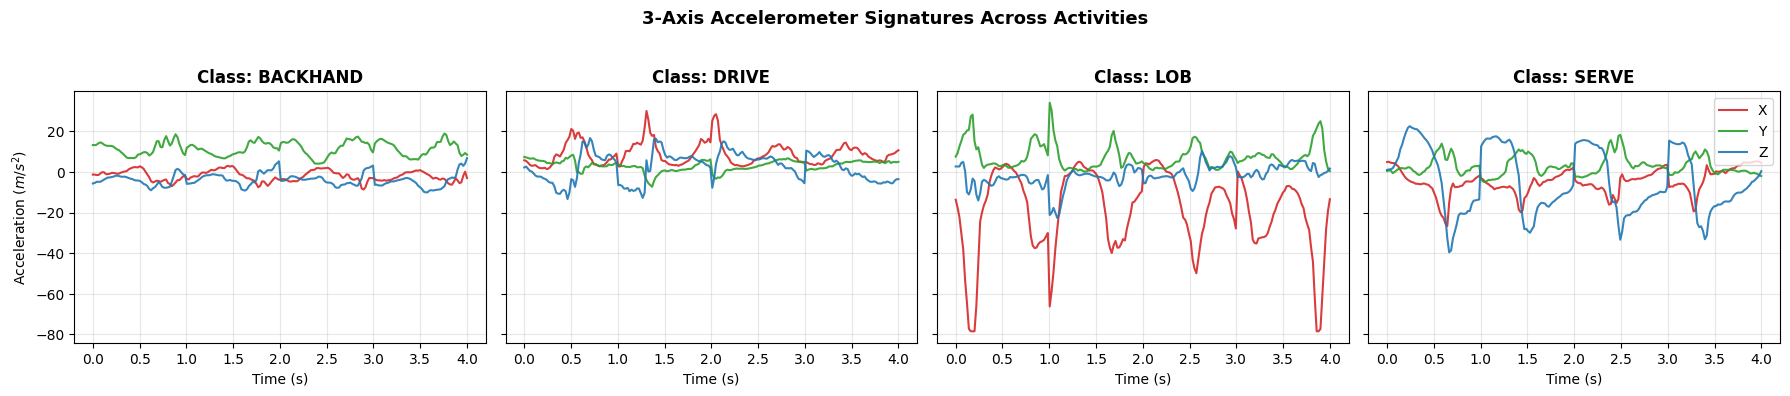

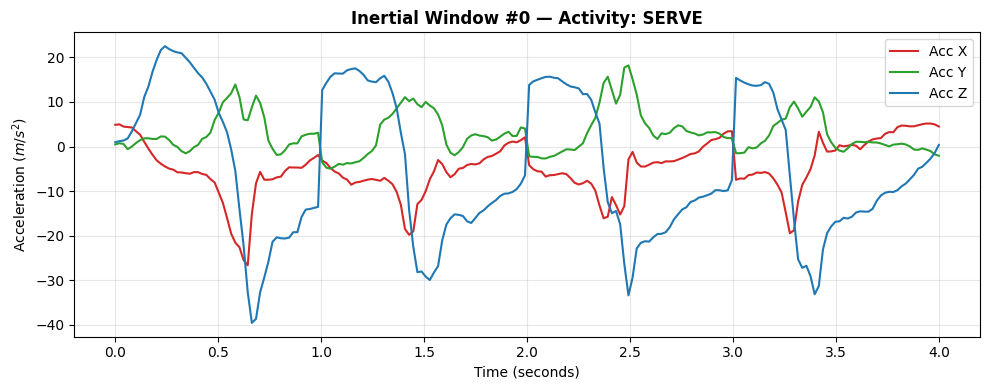

In [10]:
# Comparativa visual de una ventana representativa de cada actividad
display.plot_class_exemplars(df_train_csv, classes_list)

# Visualización detallada de una muestra individual (puedes cambiar el índice)
display.plot_sample(sample2plot=0, df_csv=df_train_csv, class_mapping=class_mapping)

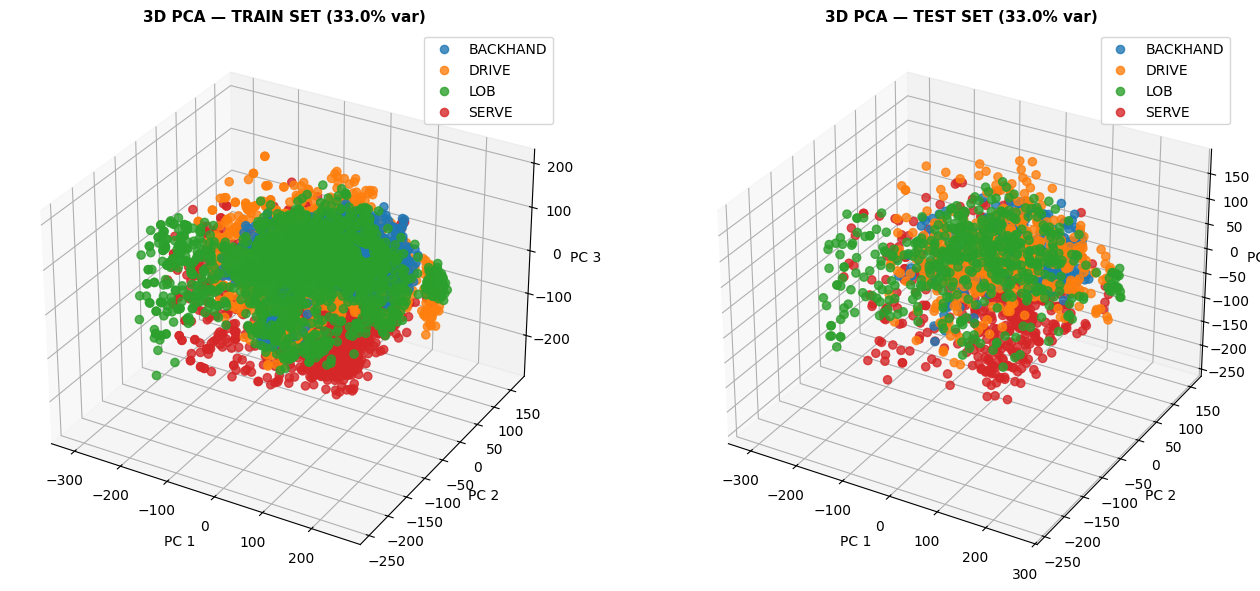

In [11]:
# Proyección en 3 Componentes Principales (PCA) del conjunto de entrenamiento y test
display.CreatePCA(df_train_csv, df_test_csv)

# 2. Experimento 1 — Clasificación Clásica sobre Señal Cruda (*Raw Data*)

Como primer punto de referencia (*baseline*), entrenamos un **Árbol de Decisión** (equivalente a J48/CART) y un **Random Forest** directamente sobre las 600 columnas de aceleración cruda (`param1..param600`).

> **Nota académica**: Un árbol de decisión evalúa condiciones puntuales del tipo `param142 <= 3.5`. Si el usuario realiza el mismo gesto medio segundo antes o después dentro de la ventana de 4 segundos, el pico de aceleración se desplaza de columna y el árbol falla.

In [12]:
# 1. Árbol de Decisión sobre señal cruda
raw_dt_results = fu.train_and_evaluate_sklearn(
    df_train_csv, df_test_csv, classifier_type="DecisionTree", max_depth=8
)
raw_dt_test_acc = raw_dt_results["test_accuracy"]

# 2. Random Forest sobre señal cruda
raw_rf_results = fu.train_and_evaluate_sklearn(
    df_train_csv, df_test_csv, classifier_type="RandomForest", n_estimators=150
)
raw_rf_test_acc = raw_rf_results["test_accuracy"]

=== [DecisionTree] Evaluation Summary ===
  Training Time : 10.322 s
  Train Accuracy: 69.50%
  Test Accuracy : 57.62% | Macro F1: 56.84%

Confusion Matrix (Test Set):
[[365  81  71  11]
 [249 152 106  21]
 [ 63  84 322  59]
 [ 17  34  99 378]]

Classification Report (Test Set):
              precision    recall  f1-score   support

    BACKHAND     0.5259    0.6913    0.5974       528
       DRIVE     0.4330    0.2879    0.3458       528
         LOB     0.5385    0.6098    0.5719       528
       SERVE     0.8060    0.7159    0.7583       528

    accuracy                         0.5762      2112
   macro avg     0.5759    0.5762    0.5684      2112
weighted avg     0.5759    0.5762    0.5684      2112

=== [RandomForest] Evaluation Summary ===
  Training Time : 39.772 s
  Train Accuracy: 100.00%
  Test Accuracy : 90.44% | Macro F1: 90.38%

Confusion Matrix (Test Set):
[[499  10  18   1]
 [ 49 435  36   8]
 [ 14  28 468  18]
 [  4   4  12 508]]

Classification Report (Test Set):
    

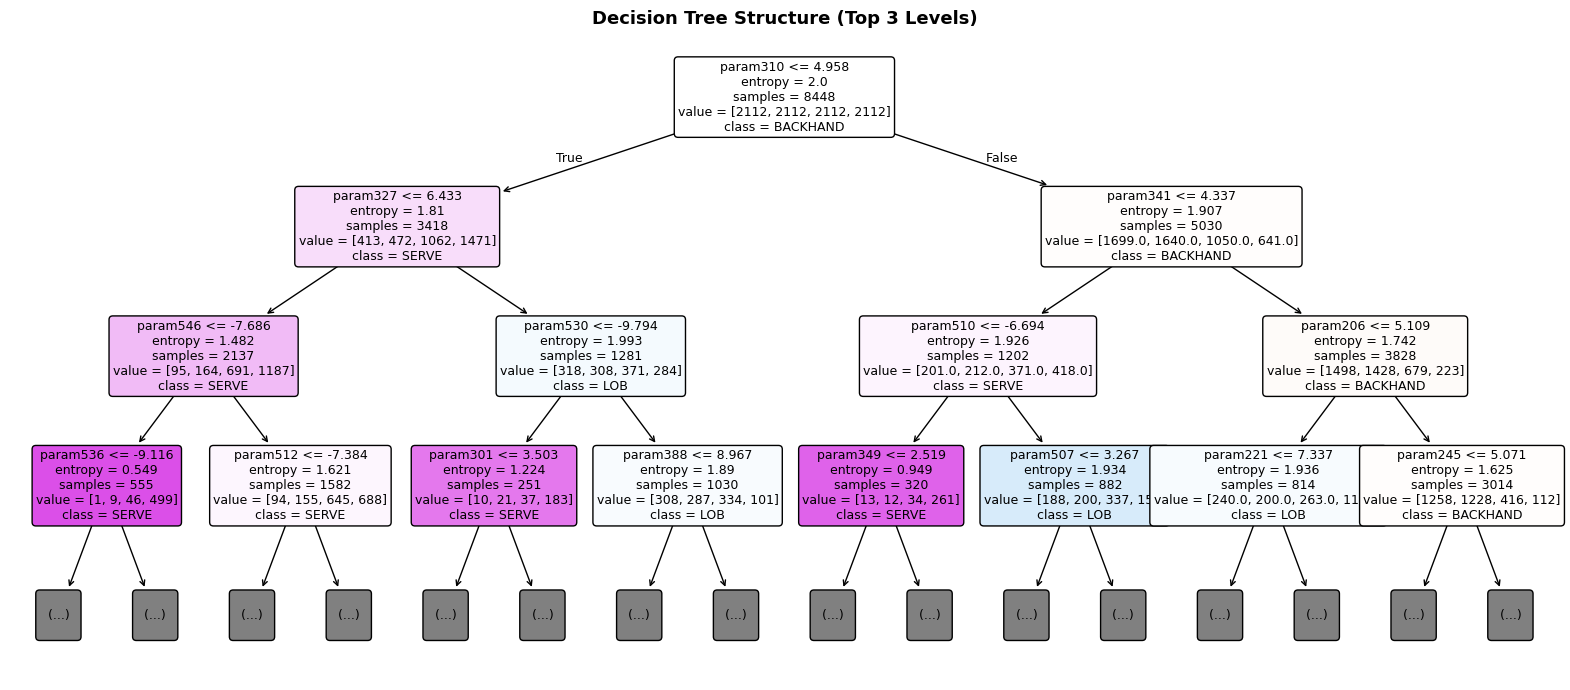

In [14]:
# Visualizar los primeros niveles del Árbol de Decisión entrenado sobre señal cruda
feature_names_raw = [f"param{i}" for i in range(1, 601)]
display.plot_decision_tree_diagram(
    raw_dt_results["model"], feature_names=feature_names_raw, class_names=classes_list, max_depth=3
)

# 3. Experimento 2 — Ingeniería de Características (*Time, Frequency & Cepstral/IMFCC*)

Para superar la limitación de usar instantes temporales aislados en clasificadores clásicos, extraemos un conjunto de **96 características físicas invariantes al desplazamiento** para cada ventana de 4 segundos:
- **Dominio Temporal y Cinemático** (por eje $X, Y, Z$ y magnitud total $SMV = \sqrt{X^2+Y^2+Z^2}$): Media, desviación típica, RMS, amplitud pico a pico, rango intercuartílico (IQR), tasa de cruces por cero (ZCR), *jerk* medio, asimetría (*skewness*), curtosis, *Signal Magnitude Area* (SMA) y correlaciones entre ejes ($\rho_{XY}, \rho_{XZ}, \rho_{YZ}$).
- **Dominio Frecuencial (FFT / PSD)**: Frecuencia dominante, centroide espectral, entropía espectral y energía por bandas (0.5–3 Hz, 3–10 Hz, 10–25 Hz).
- **Dominio Cepstral (IMFCC)**: Coeficientes cepstrales en escala Mel adaptados a señales inerciales (0–25 Hz) mediante banco de filtros triangulares y DCT-II en SciPy.

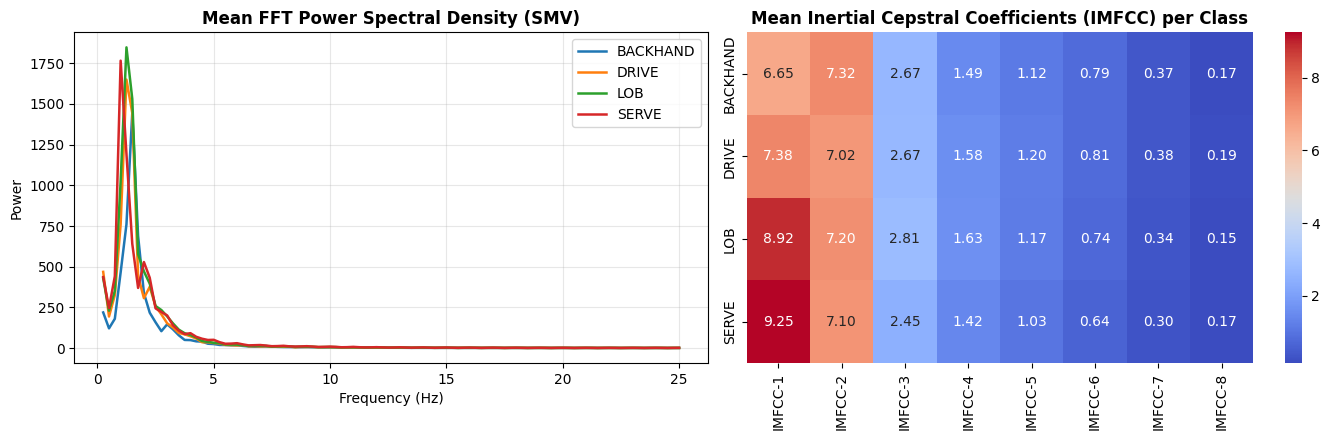

In [15]:
# Visualizar el espectro de potencia FFT medio y el perfil cepstral (IMFCC) de cada actividad
display.plot_spectral_and_cepstral_summary(df_train_csv, classes_list)

[Feature Extraction] Extracted 96 engineered features for 8448 windows in 0.807 s
[Feature Extraction] Extracted 96 engineered features for 2112 windows in 0.251 s
=== [DecisionTree] Evaluation Summary ===
  Training Time : 2.253 s
  Train Accuracy: 90.61%
  Test Accuracy : 85.75% | Macro F1: 85.83%

Confusion Matrix (Test Set):
[[430  85   8   5]
 [ 76 415  23  14]
 [ 18  25 478   7]
 [ 11  19  10 488]]

Classification Report (Test Set):
              precision    recall  f1-score   support

    BACKHAND     0.8037    0.8144    0.8090       528
       DRIVE     0.7629    0.7860    0.7743       528
         LOB     0.9210    0.9053    0.9131       528
       SERVE     0.9494    0.9242    0.9367       528

    accuracy                         0.8575      2112
   macro avg     0.8593    0.8575    0.8583      2112
weighted avg     0.8593    0.8575    0.8583      2112

=== [RandomForest] Evaluation Summary ===
  Training Time : 11.699 s
  Train Accuracy: 100.00%
  Test Accuracy : 97.96% | 

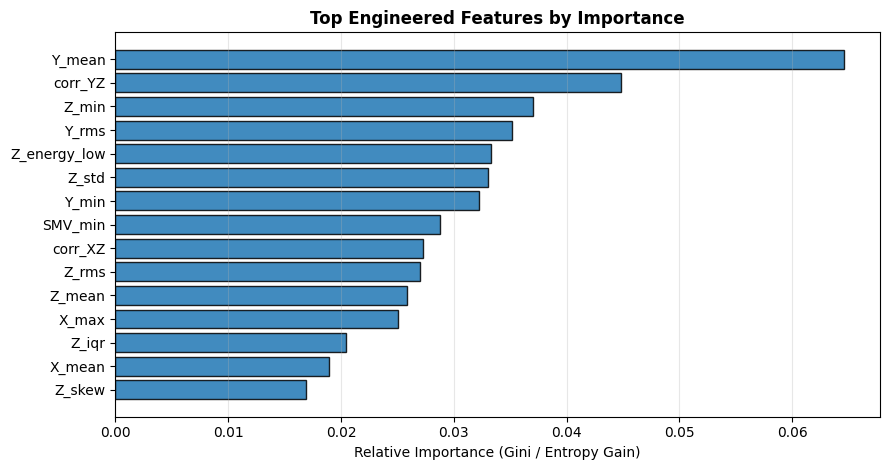

In [16]:
# Extraer características en entrenamiento y test (100% Python con NumPy/SciPy)
df_feat_train = fu.extract_inertial_features(df_train_csv, num_steps=200, fs=50.0, n_mfcc=8)
df_feat_test = fu.extract_inertial_features(df_test_csv, num_steps=200, fs=50.0, n_mfcc=8)

# Entrenar Árbol de Decisión y Random Forest sobre las características extraídas
feat_dt_results = fu.train_and_evaluate_sklearn(
    df_feat_train, df_feat_test, classifier_type="DecisionTree", max_depth=8
)
feat_dt_test_acc = feat_dt_results["test_accuracy"]

feat_rf_results = fu.train_and_evaluate_sklearn(
    df_feat_train, df_feat_test, classifier_type="RandomForest", n_estimators=150
)
feat_rf_test_acc = feat_rf_results["test_accuracy"]

# Mostrar las 15 características físicas más discriminativas
feat_names = [c for c in df_feat_train.columns if c != "class"]
display.plot_feature_importances(feat_rf_results["model"], feat_names, top_n=15)

# 4. Experimento 3 — Modelado Secuencial Profundo con Keras 3 (*LSTM*)

Los modelos recurrentes como **LSTM (*Long Short-Term Memory*)** y **GRU** procesan la señal directamente como una **secuencia ordenada de vectores 3D** a lo largo del tiempo: `(num_samples, num_steps=200, dimensions=3)`.

Gracias a sus puertas internas (*forget*, *input* y *output gates*) y a su estado de celda $c_t$, la red LSTM aprende automáticamente qué patrones dinámicos conservar a lo largo de los 200 instantes temporales sin necesidad de diseñar características manuales.

## 4.1 Preparación de Tensores Secuenciales 3D `(N, 200, 3)`

In [17]:
# Transformar cada fila de 600 columnas en un tensor secuencial (200 pasos temporales x 3 ejes)
X_train, y_train = hu.PrepareData(df_train_csv, num_steps=200, dimensions=3, classes_list=classes_list)
X_test, y_test = hu.PrepareData(df_test_csv, num_steps=200, dimensions=3, classes_list=classes_list)

[PrepareData] Samples: 8448 | X shape: (8448, 200, 3) (dtype=float32) | y shape: (8448, 4)
[PrepareData] Samples: 2112 | X shape: (2112, 200, 3) (dtype=float32) | y shape: (2112, 4)


## 4.2 Configuración y Entrenamiento del Modelo Secuencial

Puedes experimentar modificando los hiperparámetros principales:
- `network_type`: `"LSTM"` (recomendado para la Raspberry Pi), `"GRU"`, `"BiLSTM"`, `"Conv1D_LSTM"` o `"SimpleRNN"`.
- `neurons_first_layer`: Número de unidades ocultas en la capa recurrente (p. ej. `128` o `200`).
- `optimizer`: `"adam"` o `"rmsprop"` (incluyen *gradient clipping* `clipnorm=1.0` para evitar explosión de gradiente).
- `dropout`: Tasa de regularización (p. ej. `0.2`).

In [18]:
# ==============================================================================
# HIPERPARÁMETROS DEL MODELO SECUENCIAL (Modificables por el estudiante)
# ==============================================================================
network_type = "LSTM"          # Opciones: "LSTM", "GRU", "BiLSTM", "Conv1D_LSTM", "SimpleRNN"
neurons_first_layer = 128      # Número de neuronas recurrentes (p. ej. 64, 128, 200)
dropout_rate = 0.2             # Regularización Dropout (0.0 a 0.5)
optimizer_name = "adam"        # Opciones: "adam", "rmsprop", "adamw"
learning_rate = 1e-3           # Tasa de aprendizaje inicial
batch_size = 32                # Tamaño de mini-batch (16 o 32)
epochs = 60                    # Número máximo de épocas
patience = 12                  # Paciencia para EarlyStopping

# Construcción del modelo en Keras 3
model_lstm_ES = mu.CreateLSTM(
    neurons_first_layer=neurons_first_layer,
    n_steps=200,
    dimension=3,
    num_classes=num_classes,
    network_type=network_type,
    dropout=dropout_rate,
    learning_rate=learning_rate,
    optimizer=optimizer_name,
)
model_lstm_ES.summary()

# Entrenamiento del modelo
history, lstm_train_time = mu.train_sequential_model(
    model_lstm_ES,
    X_train,
    y_train,
    X_test=X_test,
    y_test=y_test,
    batch_size=batch_size,
    epochs=epochs,
    patience=patience,
)

Model: "HAR_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 128)            │        67,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 68,100 (266.02 KB)

 Trainable params: 68,100 (266.02 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/60
264/264 ━━━━━━━━━━━━━━━━━━━━ 58s 213ms/step - accuracy: 0.7042 - loss: 0.7305 - val_accuracy: 0.8125 - val_loss: 0.4867 - learning_rate: 0.0010
Epoch 2/60
264/264 ━━━━━━━━━━━━━━━━━━━━ 54s 204ms/step - accuracy: 0.8580 - loss: 0.3903 - val_accuracy: 0.8991 - val_loss: 0.2894 - learning_rate: 0.0010
Epoch 3/60
264/264 ━━━━━━━━━━━━━━━━━━━━ 84s 211ms/step - accuracy: 0.9029 - loss: 0.2801 - val_accuracy: 0.9138 - val_loss: 0.2473 - learning_rate: 0.0010
Epoch 4/60
264/264 ━━━━━━━━━━━━━━━━━━━━ 58s 219ms/step - accuracy: 0.9316 - loss: 0.2119 - val_accuracy: 0.9309 - val_loss: 0.2101 - learning_rate: 0.0010
Epoch 5/60
264/264 ━━━━━━━━━━━━━━━━━━━━ 59s 222ms/step - accuracy: 0.9427 - loss: 0.1772 - val_accuracy: 0.9588 - val_loss: 0.1261 - learning_rate: 0.0010
Epoch 6/60
264/264 ━━━━━━━━━━━━━━━━━━━━ 58s 220ms/step - accuracy: 0.9545 - loss: 0.1430 - val_accuracy: 0.9503 - val_loss: 0.1498 - learning_rate: 0.0010
Epoch 7/60
264/264 ━━━━━━━━━━━━━━━━━━━━ 57s 218ms/step - accuracy: 0.9

## 4.3 Curvas de Aprendizaje y Evaluación del Modelo Secuencial

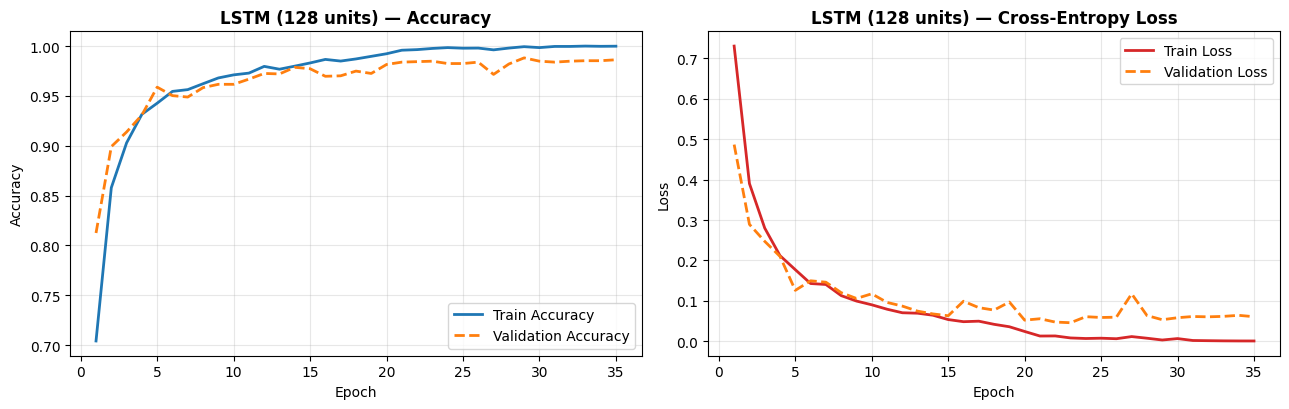

---- TRAINING RESULTS: -----
[[2110    1    1    0]
 [   4 2108    0    0]
 [   0    1 2111    0]
 [   0    0    0 2112]]
              precision    recall  f1-score   support

    BACKHAND     0.9981    0.9991    0.9986      2112
       DRIVE     0.9991    0.9981    0.9986      2112
         LOB     0.9995    0.9995    0.9995      2112
       SERVE     1.0000    1.0000    1.0000      2112

    accuracy                         0.9992      8448
   macro avg     0.9992    0.9992    0.9992      8448
weighted avg     0.9992    0.9992    0.9992      8448

Accuracy 99.9171%
---- TEST RESULTS: -----
[[523   4   1   0]
 [  9 518   1   0]
 [  3   7 515   3]
 [  0   1   3 524]]
              precision    recall  f1-score   support

    BACKHAND     0.9776    0.9905    0.9840       528
       DRIVE     0.9774    0.9811    0.9792       528
         LOB     0.9904    0.9754    0.9828       528
       SERVE     0.9943    0.9924    0.9934       528

    accuracy                         0.9848      21

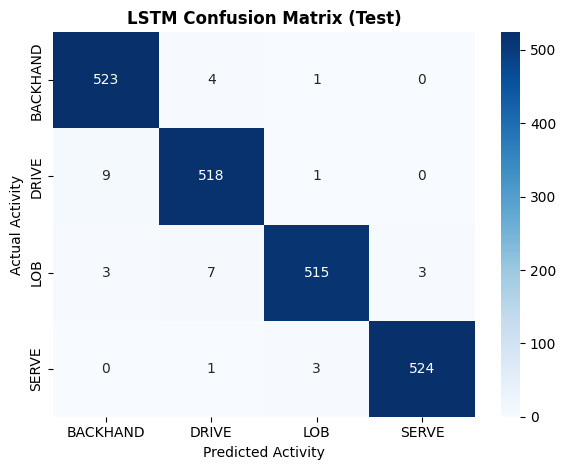

In [19]:
# 1. Curvas de evolución de Accuracy y Loss
display.plot_training_curves(history, title=f"{network_type} ({neurons_first_layer} units)")

# 2. Evaluación en Entrenamiento y Test
y_pred_train_probs = model_lstm_ES.predict(X_train, verbose=0)
y_pred_train_ES = np.argmax(y_pred_train_probs, axis=1)

y_pred_test_probs = model_lstm_ES.predict(X_test, verbose=0)
y_pred_test_ES = np.argmax(y_pred_test_probs, axis=1)

print("---- TRAINING RESULTS: -----")
mu.EvalLSTM(y_train, y_pred_train_ES, num_classes, class_names=classes_list)

print("---- TEST RESULTS: -----")
lstm_system_test_acc = mu.EvalLSTM(y_test, y_pred_test_ES, num_classes, class_names=classes_list)

# 3. Matriz de confusión gráfica
display.plot_confusion_matrix_heatmap(
    np.argmax(y_test, axis=1), y_pred_test_ES, class_names=classes_list, title=f"{network_type} Confusion Matrix (Test)"
)

In [20]:
# Inspección detallada de las distribuciones de probabilidad predichas en el conjunto de test
_ = mu.Recognize_LSTM(model_lstm_ES, X_test, y_test, class_mapping, max_rows=25)

# - actual - predicted - error - class distribution (showing 25 of 2112 samples)
1 - SERVE - LOB - yes  - [0.0003 0.0023 0.9072 0.0902]
2 - DRIVE - DRIVE - no  - [0.0176 0.9768 0.005  0.0006]
3 - LOB - LOB - no  - [0.     0.0013 0.9987 0.    ]
4 - SERVE - SERVE - no  - [0.     0.0001 0.0001 0.9998]
5 - BACKHAND - BACKHAND - no  - [0.9996 0.0001 0.0001 0.0002]
6 - SERVE - SERVE - no  - [0.     0.     0.0002 0.9998]
7 - DRIVE - DRIVE - no  - [0.0002 0.9997 0.0001 0.    ]
8 - DRIVE - DRIVE - no  - [0.0001 0.9997 0.0002 0.    ]
9 - LOB - LOB - no  - [0.0001 0.0006 0.9989 0.0004]
10 - BACKHAND - BACKHAND - no  - [0.9999 0.0001 0.     0.    ]
11 - SERVE - SERVE - no  - [0. 0. 0. 1.]
12 - BACKHAND - BACKHAND - no  - [0.9999 0.0001 0.     0.    ]
13 - SERVE - SERVE - no  - [0. 0. 0. 1.]
14 - LOB - LOB - no  - [0.     0.0001 0.9999 0.    ]
15 - SERVE - SERVE - no  - [0.     0.     0.0001 0.9998]
16 - LOB - LOB - no  - [0.     0.0001 0.9999 0.    ]
17 - BACKHAND - BACKHAND - no  - [0.9996 0.0002

## 4.4 Exportación del Modelo para la Raspberry Pi (`demo-lstm-recognizer.py`)

Guardamos la arquitectura (`.json`), los pesos en formato Keras 3 (`.weights.h5`) y la lista ordenada de clases (`.classes.txt`) en la carpeta `models/`.

In [21]:
models_dir = os.path.join(general_path, "models")
model_name_suffix = "-LSTM_from_raw"

out_path_model_lstm_json, out_path_model_lstm_h5 = mu.save_model_for_raspi(
    model=model_lstm_ES,
    models_dir=models_dir,
    root_class_list=root_class_list,
    model_name=model_name_suffix,
    classes_list=classes_list,
)

[NEW MODEL][Successfully saved for Raspberry Pi!]
	MODEL PREFIX : BACKHAND_DRIVE_LOB_SERVE-LSTM_from_raw
	.json file   : /content/IE-workspace/HAR_INERCIAL_v2/models/BACKHAND_DRIVE_LOB_SERVE-LSTM_from_raw.json
	.weights.h5  : /content/IE-workspace/HAR_INERCIAL_v2/models/BACKHAND_DRIVE_LOB_SERVE-LSTM_from_raw.weights.h5
	.classes.txt : /content/IE-workspace/HAR_INERCIAL_v2/models/BACKHAND_DRIVE_LOB_SERVE-LSTM_from_raw.classes.txt


In [22]:
# Verificación de carga desde disco (simulando la carga que realizará la Raspberry Pi)
loaded_model = mu.load_saved_model(out_path_model_lstm_json, out_path_model_lstm_h5)
y_verify = loaded_model.predict(X_test[:5], verbose=0)
print("Predicciones verificadas en las primeras 5 muestras de test:\n", np.round(y_verify, 4))

[Model successfully loaded from /content/IE-workspace/HAR_INERCIAL_v2/models/BACKHAND_DRIVE_LOB_SERVE-LSTM_from_raw.json and /content/IE-workspace/HAR_INERCIAL_v2/models/BACKHAND_DRIVE_LOB_SERVE-LSTM_from_raw.weights.h5]
Predicciones verificadas en las primeras 5 muestras de test:
 [[3.000e-04 2.300e-03 9.072e-01 9.020e-02]
 [1.760e-02 9.768e-01 5.000e-03 6.000e-04]
 [0.000e+00 1.300e-03 9.987e-01 0.000e+00]
 [0.000e+00 1.000e-04 1.000e-04 9.998e-01]
 [9.996e-01 1.000e-04 1.000e-04 2.000e-04]]


# 5. Experimento 4 — Comparativa Estadística de Sistemas (Intervalos de Confianza al 95%)

Finalmente comparamos la precisión alcanzada en el conjunto de test por los distintos paradigmas evaluados a lo largo de la práctica, teniendo en cuenta el tamaño muestral $N_{\text{test}}$ mediante intervalos de confianza al 95%:
$$CI_{95\%} = 1.96 \sqrt{\frac{\text{acc} \cdot (100 - \text{acc})}{N_{\text{test}}}}$$

=== Statistical Systems Comparison (Test Set N = 2112, 95% CI) ===
  Raw Data + Decision Tree        :  57.62%  ±  2.11%  -> 95% CI: [ 55.52%,  59.73%]
  Raw Data + Random Forest        :  90.44%  ±  1.25%  -> 95% CI: [ 89.18%,  91.69%]
  Engineered Feats + Decision Tree:  85.75%  ±  1.49%  -> 95% CI: [ 84.26%,  87.24%]
  Engineered Feats + Random Forest:  97.96%  ±  0.60%  -> 95% CI: [ 97.36%,  98.57%]
  Deep Sequential (LSTM)          :  98.48%  ±  0.52%  -> 95% CI: [ 97.96%,  99.01%]


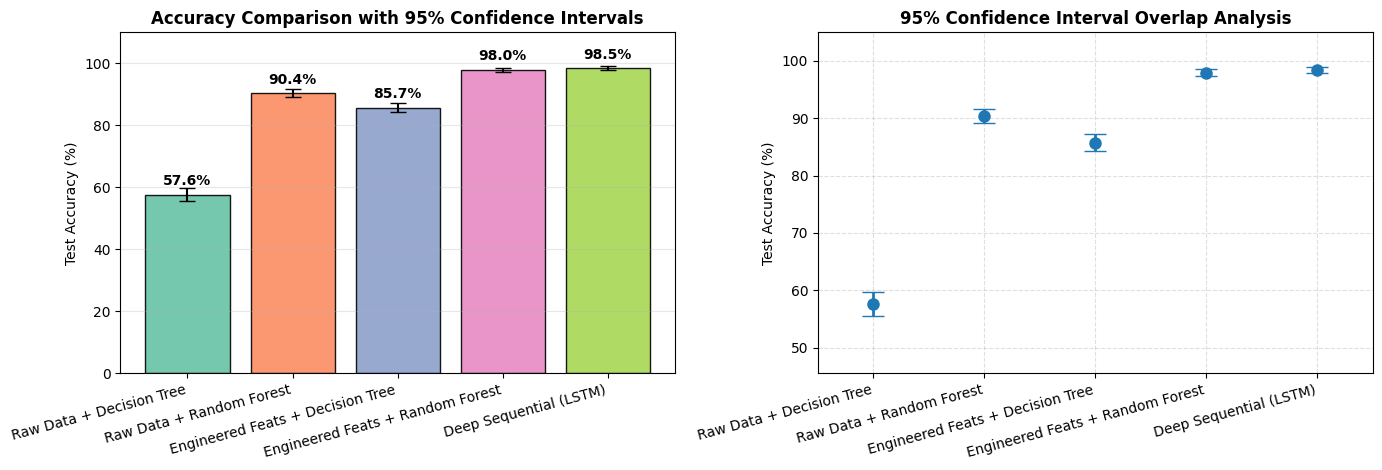

In [23]:
num_samples_test = len(y_test)

comparison_results = {
    "Raw Data + Decision Tree": raw_dt_test_acc,
    "Raw Data + Random Forest": raw_rf_test_acc,
    "Engineered Feats + Decision Tree": feat_dt_test_acc,
    "Engineered Feats + Random Forest": feat_rf_test_acc,
    f"Deep Sequential ({network_type})": lstm_system_test_acc,
}

display.plot_systems_comparison(comparison_results, num_samples_test)